# Hw2.3 — Топ-50 книг Amazon (2009–2019)
Датасет із Kaggle: *Amazon Top 50 Bestselling Books 2009–2019*

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="darkgrid", palette="Set2")

def ans(question, answer):
    print(f"❓ {question}\n✅ Відповідь: {answer}\n")

## Читання даних

In [2]:

FILE = "bestsellers with categories.csv"
try:
    df = pd.read_csv(FILE)
except FileNotFoundError:
    FILE = glob.glob("*bestsellers*.csv")[0]
    df = pd.read_csv(FILE)
df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [3]:
df.shape

(550, 7)

In [4]:
ans("Про скільки книг зберігає дані датасет?", df.shape[0])

❓ Про скільки книг зберігає дані датасет?
✅ Відповідь: 550



In [5]:
df.columns = ["name", "author", "user_rating", "reviews", "price", "year", "genre"]
df.head()

,name,author,user_rating,reviews,price,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


## Первинне дослідження даних

In [6]:
print(df.isna().sum())
ans("Чи є в якихось змінних пропуски?", "Так" if df.isna().any().any() else "Ні")

name           0
author         0
user_rating    0
reviews        0
price          0
year           0
genre          0
dtype: int64
❓ Чи є в якихось змінних пропуски?
✅ Відповідь: Ні



In [7]:
ans("Які є унікальні жанри?", list(df["genre"].unique()))

❓ Які є унікальні жанри?
✅ Відповідь: ['Non Fiction', 'Fiction']



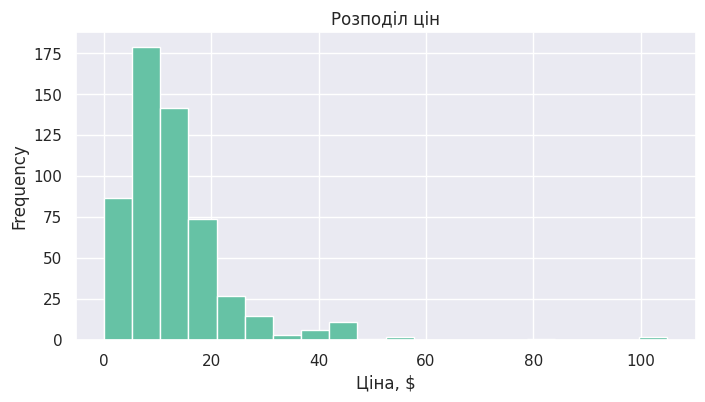

In [8]:
df["price"].plot(kind="hist", bins=20, figsize=(8, 4), title="Розподіл цін")
plt.xlabel("Ціна, $")
plt.show()

In [9]:
ans("Максимальна ціна?", df["price"].max())
ans("Мінімальна ціна?", df["price"].min())
ans("Середня ціна?", round(df["price"].mean(), 2))
ans("Медіанна ціна?", df["price"].median())

❓ Максимальна ціна?
✅ Відповідь: 105

❓ Мінімальна ціна?
✅ Відповідь: 0

❓ Середня ціна?
✅ Відповідь: 13.1

❓ Медіанна ціна?
✅ Відповідь: 11.0



## Пошук та сортування даних

In [10]:
max_rating = df["user_rating"].max()
ans("Який рейтинг у датасеті найвищий?", max_rating)
ans("Скільки книг мають такий рейтинг?", (df["user_rating"] == max_rating).sum())

❓ Який рейтинг у датасеті найвищий?
✅ Відповідь: 4.9

❓ Скільки книг мають такий рейтинг?
✅ Відповідь: 52



In [11]:
ans("Яка книга має найбільше відгуків?", df.loc[df["reviews"].idxmax(), "name"])

❓ Яка книга має найбільше відгуків?
✅ Відповідь: Where the Crawdads Sing



In [12]:
books_2015 = df[df["year"] == 2015]
ans("Яка книга найдорожча серед Топ-50 2015 року?",
    books_2015.sort_values("price", ascending=False).iloc[0]["name"])

❓ Яка книга найдорожча серед Топ-50 2015 року?
✅ Відповідь: Publication Manual of the American Psychological Association, 6th Edition



In [13]:
ans("Скільки книг жанру Fiction потрапили до Топ-50 у 2010 році?",
    df[(df["genre"] == "Fiction") & (df["year"] == 2010)].shape[0])

❓ Скільки книг жанру Fiction потрапили до Топ-50 у 2010 році?
✅ Відповідь: 20



In [14]:
ans("Скільки книг з рейтингом 4.9 потрапило до рейтингу у 2010 та 2011 роках?",
    df[(df["user_rating"] == 4.9) & (df["year"].isin([2010, 2011]))].shape[0])

❓ Скільки книг з рейтингом 4.9 потрапило до рейтингу у 2010 та 2011 роках?
✅ Відповідь: 1



In [15]:
cheap_2015 = df[(df["year"] == 2015) & (df["price"] < 8)].sort_values("price")
display(cheap_2015)
ans("Яка книга остання у відсортованому списку?", cheap_2015.iloc[-1]["name"])

,name,author,user_rating,reviews,price,year,genre
507,To Kill a Mockingbird,Harper Lee,4.8,26234,0,2015,Fiction
54,Creative Haven Creative Cats Coloring Book (Ad...,Marjorie Sarnat,4.8,4022,4,2015,Non Fiction
206,Knock-Knock Jokes for Kids,Rob Elliott,4.5,3673,4,2015,Non Fiction
111,First 100 Words,Roger Priddy,4.7,17323,4,2015,Non Fiction
210,Laugh-Out-Loud Jokes for Kids,Rob Elliott,4.6,6990,4,2015,Non Fiction
123,Giraffes Can't Dance,Giles Andreae,4.8,14038,4,2015,Fiction
55,Creative Haven Owls Coloring Book (Adult Color...,Marjorie Sarnat,4.8,3871,5,2015,Non Fiction
63,Dear Zoo: A Lift-the-Flap Book,Rod Campbell,4.8,10922,5,2015,Fiction
224,Love You Forever,Robert Munsch,4.8,18613,5,2015,Fiction
478,The Very Hungry Caterpillar,Eric Carle,4.9,19546,5,2015,Fiction


❓ Яка книга остання у відсортованому списку?
✅ Відповідь: Old School (Diary of a Wimpy Kid #10)



## Агрегування даних та з'єднання таблиць

In [16]:
price_by_genre = df.groupby("genre").agg({"price": ["max", "min"]})
price_by_genre

price    
              max min
genre                
Fiction        82   0
Non Fiction   105   0

In [17]:
ans("Максимальна ціна для жанру Fiction", price_by_genre.loc["Fiction", ("price", "max")])
ans("Мінімальна ціна для жанру Fiction", price_by_genre.loc["Fiction", ("price", "min")])
ans("Максимальна ціна для жанру Non Fiction", price_by_genre.loc["Non Fiction", ("price", "max")])
ans("Мінімальна ціна для жанру Non Fiction", price_by_genre.loc["Non Fiction", ("price", "min")])

❓ Максимальна ціна для жанру Fiction
✅ Відповідь: 82

❓ Мінімальна ціна для жанру Fiction
✅ Відповідь: 0

❓ Максимальна ціна для жанру Non Fiction
✅ Відповідь: 105

❓ Мінімальна ціна для жанру Non Fiction
✅ Відповідь: 0



In [18]:
books_count = df.groupby("author").agg({"name": "count"}).rename(columns={"name": "books"})
ans("Якої розмірності вийшла таблиця?", books_count.shape)
ans("Який автор має найбільше книг?", books_count["books"].idxmax())
ans("Скільки книг цього автора?", books_count["books"].max())

❓ Якої розмірності вийшла таблиця?
✅ Відповідь: (248, 1)

❓ Який автор має найбільше книг?
✅ Відповідь: Jeff Kinney

❓ Скільки книг цього автора?
✅ Відповідь: 12



In [19]:
avg_rating = df.groupby("author").agg({"user_rating": "mean"}).rename(columns={"user_rating": "mean_rating"})
ans("У якого автора середній рейтинг мінімальний?", avg_rating["mean_rating"].idxmin())
ans("Який у цього автора середній рейтинг?", round(avg_rating["mean_rating"].min(), 2))

❓ У якого автора середній рейтинг мінімальний?
✅ Відповідь: Donna Tartt

❓ Який у цього автора середній рейтинг?
✅ Відповідь: 3.9



In [20]:
authors = pd.concat([books_count, avg_rating], axis=1)
authors = authors.sort_values(["books", "mean_rating"], ascending=[True, True])
display(authors.head())
ans("Який автор перший у списку?", authors.index[0])

,books,mean_rating
author,,
Muriel Barbery,1,4.0
Chris Cleave,1,4.1
Ian K. Smith M.D.,1,4.1
Pierre Dukan,1,4.1
Elizabeth Strout,1,4.2


❓ Який автор перший у списку?
✅ Відповідь: Muriel Barbery



---
## Візуалізація (додаткові графіки)

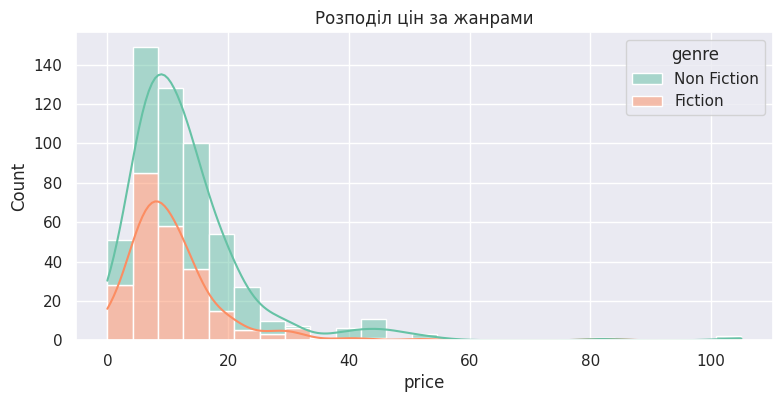

In [21]:

plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="price", hue="genre", kde=True, bins=25, multiple="stack")
plt.title("Розподіл цін за жанрами")
plt.show()

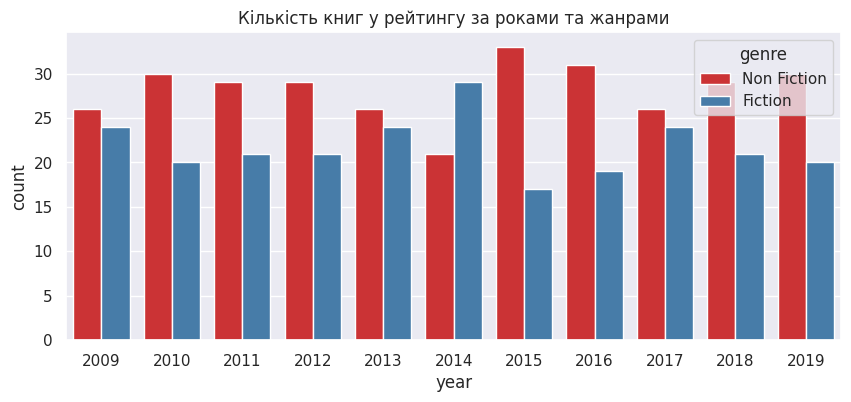

In [22]:

plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="year", hue="genre", palette="Set1")
plt.title("Кількість книг у рейтингу за роками та жанрами")
plt.show()

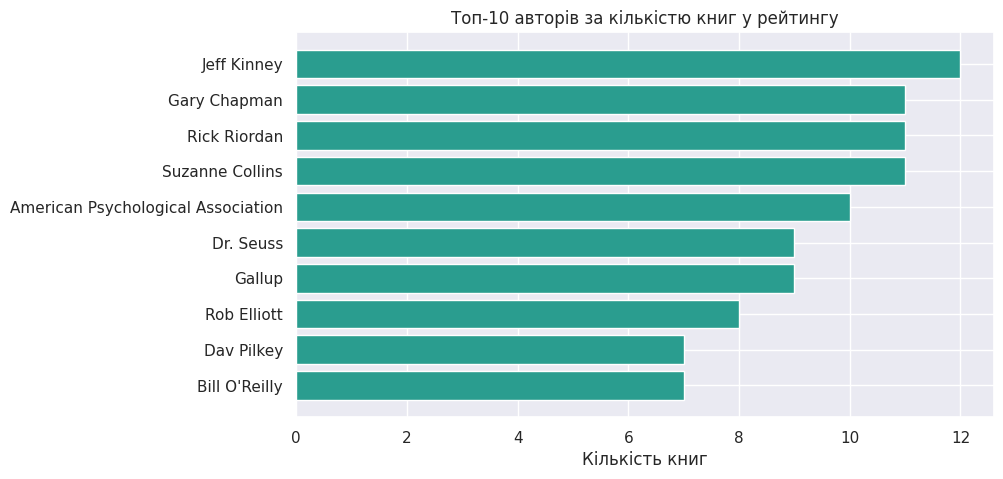

In [23]:

top_authors = books_count["books"].sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5))
plt.barh(top_authors.index[::-1], top_authors.values[::-1], color="#2a9d8f")
plt.title("Топ-10 авторів за кількістю книг у рейтингу")
plt.xlabel("Кількість книг")
plt.show()

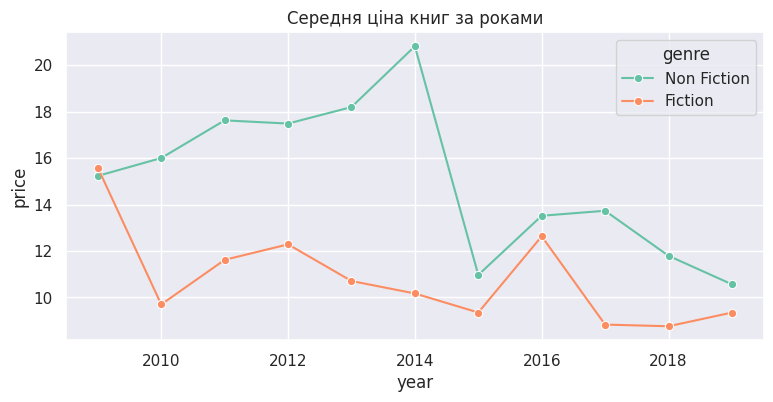

In [24]:

plt.figure(figsize=(9, 4))
sns.lineplot(data=df, x="year", y="price", hue="genre", marker="o", errorbar=None)
plt.title("Середня ціна книг за роками")
plt.show()

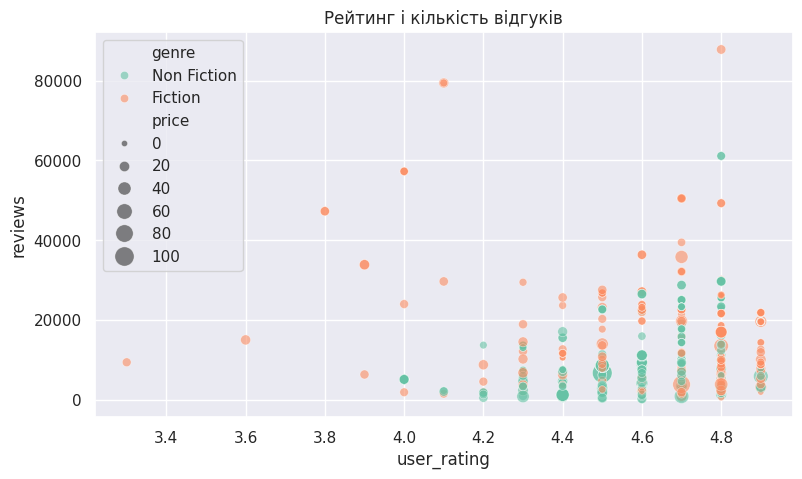

In [25]:

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="user_rating", y="reviews", hue="genre", size="price", alpha=.6, sizes=(20, 200))
plt.title("Рейтинг і кількість відгуків")
plt.show()